The DFT produces a spectrum, but it doesn't retain information about time dynamics.

To see _when_ frequencies appear, we need to chop it into windows, and run the DFT on each one.

Let's give it a shot.

We'll start by generating a test sound that contains 10 different frequencies over one second. To keep it simple, we'll stitch together ten 0.1 second clips, each of which will contain a sound consisting of two frequencies.

In [146]:
# TODO: generate

In [ ]:
# TODO: plot

Next, we'll chop it into 0.1 second segments. This should allow our DFT to reproduce the spectrum perfectly for each window.

In [147]:
# TODO: chop

In [148]:
# TODO: DFT

In [149]:
# TODO: plot

...Well, that looks odd.

Our window should contain spikes at two frequencies, not...However many _that_ is.

Let's look at the windows side by side...

In [ ]:
# TODO: side-by-side windows

Looks like a wave; nothing is obviously wrong.

But take a look at the endpoints: Notice how the _ends_ of each window don't match their _beginnings_. There's a vertical gap between the final value of each window, and the first.

In [150]:
# TODO: show

This wasn't the case with the test sound we used before.

In [151]:
# TODO: show end = beginning

At a glance, this is the only difference I can see.

It's a big hint: The test sound is _perfectly periodic_. The section we fed into our DFT could repeat forever. The chopped-up signal is _not_ periodic; the end and beginning don't line up.

Recall that the DFT is _itself_ a function. The DFT is based on sinusoids, which are periodic. That might mean the DFT _itself_ is periodic.

So maybe the problem is: We're trying to use it to decompose a signal that is _not_ periodic, using _only_ periodic building blocks. If that were the case, it would stand to reason that we need to use a lot of them to approximate something that fundamentally isn't.

If a function is periodic, it repeats itself after some period of time, called...Well, a **period**. To show the DFT is periodic, we'd need to show that it repeats itself after some length of time.

In other words, we'd need to show:

$$
DFT(x + N) = DFT(x)
$$

...For some $ N $, which represents our period.

TODO
- Windows
  - Pull: 4-Up, etc.
  - The more we smooth, the better it gets.
  - ...But the more we smooth, the, well, more we have to smooth: This starts to degrade data closer to the center of our window.
  - Seems like _when_ vs _what_ is a tradeoff.
- Once windowed, can proceed and compute/plot spectrogram
- Observe the frequency buckets. Let's cross-check formants, and...Wait. We might not be able to see some of these.
- Window _size_ matters too: **Wideband** vs **narrowband**.
- "Interlude": Gabor limit.
- "Interlude": Psychoacoustics, Dynamic Range and the Exponential Chirp
- Mel/Bark Spectrograms

So the DFT _is_ periodic: It treats our input signal as if it repeats forever.

Now we can see the problem. When the ends of windows we pass in don't align with their beginnings, the DFT just links them up with a vertical line, and pretends it's part of the actual signal.

This means that, in addition to frequencies that really do occur in your signal, the DFT will _also_ include whichever frequencies it needs to recreate the vertical spike.

This turns out to be...Unfortunate, depending on your perspective.

A vertical spike is called an **impulse**. Impulses like this are [jump discontinuities](https://en.wikipedia.org/wiki/Classification_of_discontinuities#Jump_discontinuity); the value you get approaching from the left is different from the one you get approaching from the right, _and_ the difference occurs over an infinitesimal distance.

In our case, an impulse is simply a signal consisting of the single value `1`. This can be formalized with the [Kronecker delta function](https://en.wikipedia.org/wiki/Kronecker_delta):

$$
\delta_{ij} = \begin{cases} 1 & \text{if } i=j \\ 0 & \text{if } i\neq j \end{cases}
$$

The plot below shows what these jumps look like.

The top row is what we have now: Sharp edges with large gaps. The bottom row uses a tool we'll see in a moment to force the edges to zero. As far as the DFT is concerned, this is much nicer.

**Note**: The plot uses dummy data rather than our test sound, because the noisy signal is more visually illustrative—but the same point would hold.

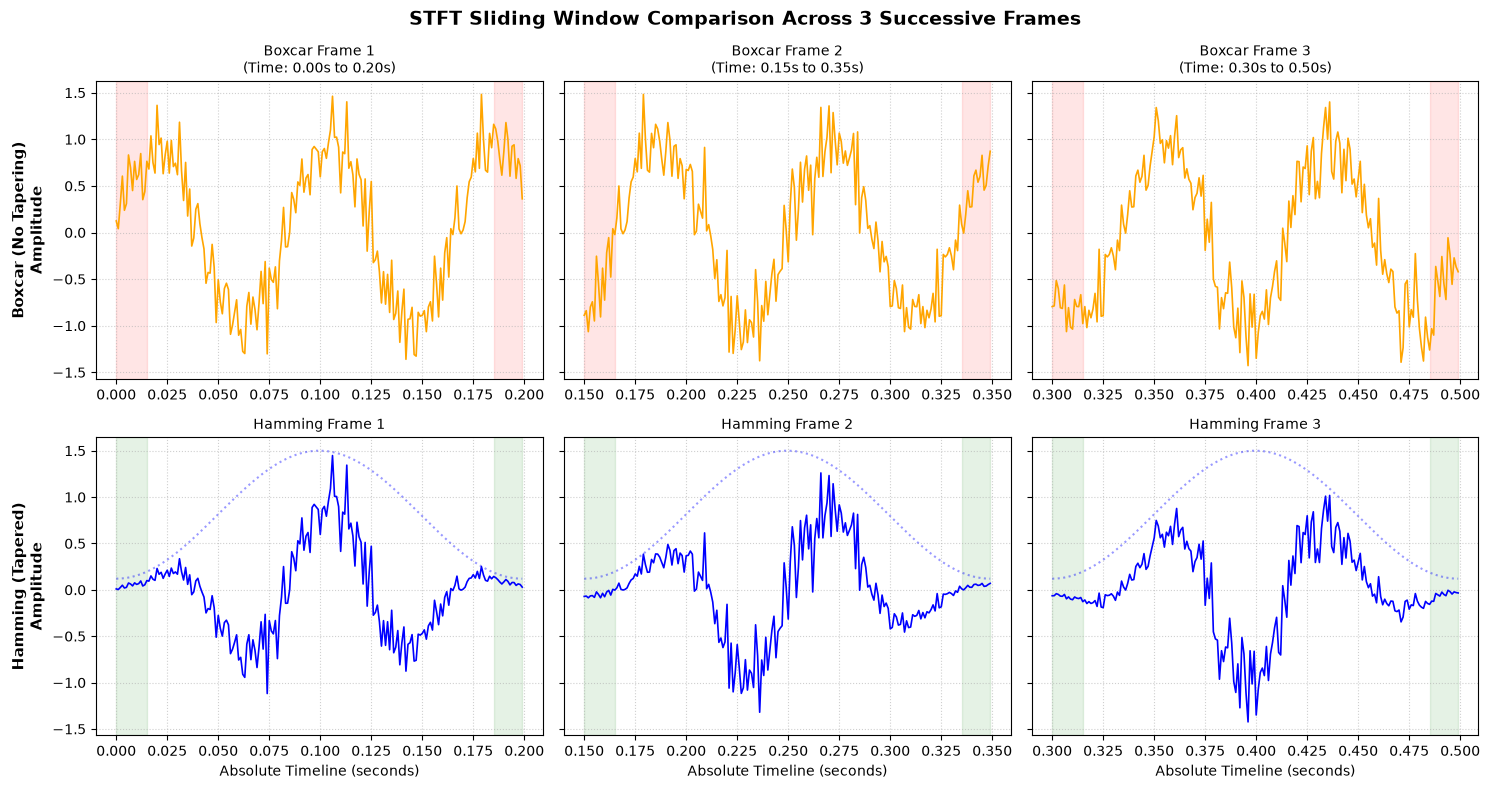

In [250]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal.windows as windows

# 1. Configuration & Parameters
np.random.seed(42)
fs = 1000          # Sampling Frequency (Hz)
f = 12             # Frequency of signal (Hz)
frame_len = 200    # Length of a single frame (200 ms per frame)
hop_size = 150     # Overlap layout (50 samples / 25% overlap for visualization)

# Generate a continuous noisy signal long enough to pull 3 distinct frames
t_total = 0.6
t_sig = np.linspace(0, t_total, int(fs * t_total), endpoint=False)
signal = np.sin(2 * np.pi * f * t_sig) + np.random.normal(0, 0.25, size=t_sig.shape)

# Window profiles
w_boxcar = windows.boxcar(frame_len)
w_hamming = windows.hamming(frame_len)

# 2. Extract 3 overlapping frames
frame_indices = [0 * hop_size, 1 * hop_size, 2 * hop_size]

fig, axs = plt.subplots(2, 3, figsize=(15, 8), sharey='row')

for i, start_idx in enumerate(frame_indices):
    end_idx = start_idx + frame_len
    frame_t = t_sig[start_idx:end_idx]
    frame_data = signal[start_idx:end_idx]
    
    # --- ROW 1: BOXCAR (RECTANGULAR) ---
    boxcar_data = frame_data * w_boxcar
    axs[0, i].plot(frame_t, boxcar_data, color='orange', linewidth=1.2)
    # Highlight the harsh boundaries
    axs[0, i].axvspan(frame_t[0], frame_t[15], color='red', alpha=0.1)
    axs[0, i].axvspan(frame_t[-15], frame_t[-1], color='red', alpha=0.1)
    axs[0, i].set_title(f"Boxcar Frame {i+1}\n(Time: {frame_t[0]:.2f}s to {frame_t[-1]:.2f}s)", fontsize=10)
    axs[0, i].grid(True, linestyle=':', alpha=0.6)
    
    # --- ROW 2: HAMMING ---
    hamming_data = frame_data * w_hamming
    axs[1, i].plot(frame_t, hamming_data, color='blue', linewidth=1.2)
    axs[1, i].plot(frame_t, w_hamming * 1.5, color='blue', linestyle=':', alpha=0.4) # scale envelope for visibility
    # Highlight smooth fading boundaries
    axs[1, i].axvspan(frame_t[0], frame_t[15], color='green', alpha=0.1)
    axs[1, i].axvspan(frame_t[-15], frame_t[-1], color='green', alpha=0.1)
    axs[1, i].set_title(f"Hamming Frame {i+1}", fontsize=10)
    axs[1, i].grid(True, linestyle=':', alpha=0.6)
    axs[1, i].set_xlabel("Absolute Timeline (seconds)")

# Formatting structural labels
axs[0, 0].set_ylabel("Boxcar (No Tapering)\nAmplitude", fontsize=11, weight='bold')
axs[1, 0].set_ylabel("Hamming (Tapered)\nAmplitude", fontsize=11, weight='bold')

plt.suptitle("STFT Sliding Window Comparison Across 3 Successive Frames", fontsize=14, weight='bold', y=0.98)
plt.tight_layout()
plt.show()

As we said, the DFT will include whatever it needs to model this as part of its output. Let's see what that entails, so we understand what exactly smoothing the edges fixes.

In [152]:
# TODO: DFT of impulse signal 

So...The impulse signal, the humble value 1, contains _every_ frequency.

...Yeah. That's not a mistake. 

Intuitively: Imagine stacking up every _possible_ complex exponential. At the origin, every cosine component equals one; every sine component equals zero. Outside of the origin, you have an infinite number of waves at every possible frequency; they cancel each other out an infinitesimal distance from the origin. Because we have an infinite number of cosines, the spike goes to infinity; but remains zero everywhere else.

I'm waving my hands, because explaining this fully requires machinery we haven't yet developed. We'll see it again at least twice, treating it formally then:
- At the end of this section, when we discuss tradeoffs in spectrogram resolution. We'll see how the relationship between time and frequency force the impulse to contain all frequencies. 
- At the very end of this Arc, when we derive the continuous Fourier transform algebraically. We'll _prove_ the impulse contains every frequency by computing the Fourier transform of the [Dirac delta function](https://en.wikipedia.org/wiki/Dirac_delta_function), the continuous version of the discrete Kronecker delta we used above.
- In an accompanying tour of [Max 4 Live](https://www.ableton.com/en/live/max-for-live/), where we'll revisit its use to study the [impulse response](https://en.wikipedia.org/wiki/Impulse_response) of filters we design...But don't hold your breath for this.

The takeaway for now: Jump discontinuities lead to the DFT "diluting" the spectrum. Instead of properly computing the contributions of all constituent frequencies, it includes nonexistent ones, causing signal that should contribute to "real" components _leaking_ into the representation of the impulse.

This is called [spectral leakage](https://en.wikipedia.org/wiki/Spectral_leakage), and we hate it.

Because this is due to jump discontinuities at window boundaries, a solution presents itself immediately: Eliminate the discontinuity.

This implies _not_ using a naive rectangle to enframe the signal. Instead, we could use something more sophisticated, that forces each frame to be periodic.

## Window Functions

We have several options; we'll take a look at three of the most popular, alongside our erstwhile boxcar.

In [237]:
from scipy.signal import windows

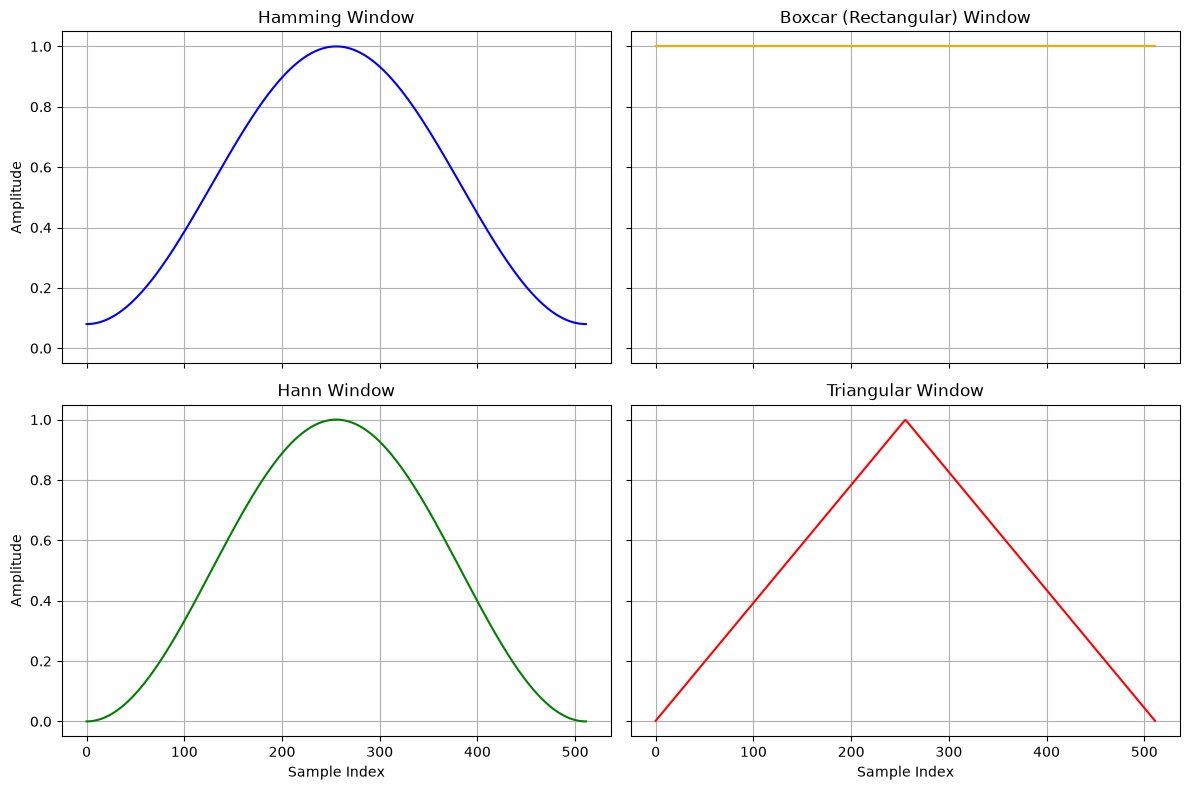

In [238]:
# Gemini
# Define the number of points in the window
M = 512

# Generate the window functions
w_hamming = windows.hamming(M)
w_boxcar = windows.boxcar(M)
w_hann = windows.hann(M)
w_triang = windows.triang(M)

# Create a 2x2 subplot grid
fig, axs = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)

# Plot Hamming Window
axs[0, 0].plot(w_hamming, color='blue')
axs[0, 0].set_title('Hamming Window')
axs[0, 0].grid(True)

# Plot Boxcar (Rectangular) Window
axs[0, 1].plot(w_boxcar, color='orange')
axs[0, 1].set_title('Boxcar (Rectangular) Window')
axs[0, 1].grid(True)

# Plot Hann Window
axs[1, 0].plot(w_hann, color='green')
axs[1, 0].set_title('Hann Window')
axs[1, 0].set_xlabel('Sample Index')
axs[1, 0].grid(True)

# Plot Triangular Window
axs[1, 1].plot(w_triang, color='red')
axs[1, 1].set_title('Triangular Window')
axs[1, 1].set_xlabel('Sample Index')
axs[1, 1].grid(True)

# Set common Y-labels
for ax in axs[:, 0]:
    ax.set_ylabel('Amplitude')

plt.tight_layout()
plt.show()

Everything except the boxcar _tapers_ at the edges: This helps attenuate the signal on either end of a frame to restore periodicity.

Recall that we multiply each window elementwise against each frame.

We've seen what a frame looks like using the boxcar. Here's one using the Hamming window.

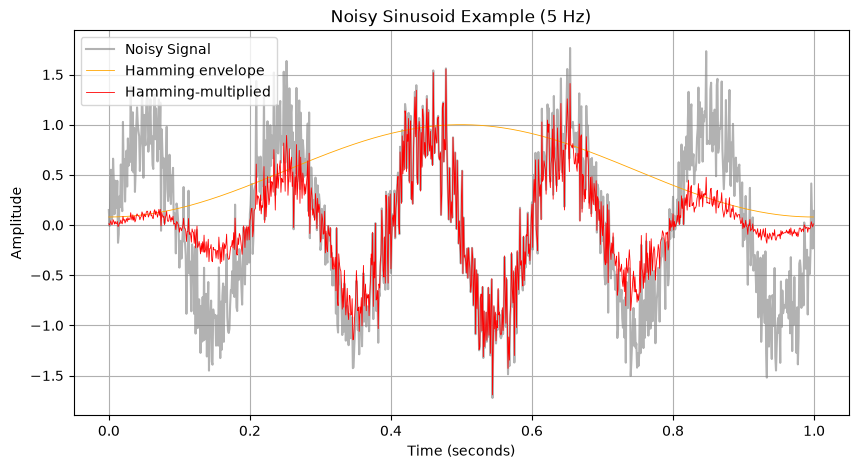

In [254]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Set a random seed for reproducibility
np.random.seed(42)

# 2. Define parameters
fs = 1000          # Sampling frequency (Hz)
t_max = 1.0        # Duration in seconds
f = 5              # Frequency of the sine wave (Hz)
amplitude = 1.0    # Amplitude of the sine wave
noise_std = 0.3    # Standard deviation (intensity) of the noise

# 3. Generate time vector and clean sine wave
t = np.linspace(0, t_max, int(fs * t_max), endpoint=False)
clean_signal = amplitude * np.sin(2 * np.pi * f * t)

# 4. Generate Gaussian noise and add it to the signal
noise = np.random.normal(loc=0.0, scale=noise_std, size=t.shape)
noisy_signal = clean_signal + noise

# 5. Plot the results
plt.figure(figsize=(10, 5))
plt.plot(t, noisy_signal, label='Noisy Signal', color='gray', alpha=0.6)
plt.plot(t, windows.hamming(int(fs * t_max)), label='Hamming envelope', color='orange', linewidth=0.6, linestyle='-')
plt.plot(t, windows.hamming(int(fs * t_max)) * noisy_signal, label='Hamming-multiplied', color='red', linewidth=0.6)
plt.title(f'Noisy Sinusoid Example ({f} Hz)')
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)
plt.show()

Note that the Hamming window retains the signal's shape in the center, but attenuates its edges to zero. This helps resolve the broken periodicity assumption. 

Let's look at four common windows side-by-side.

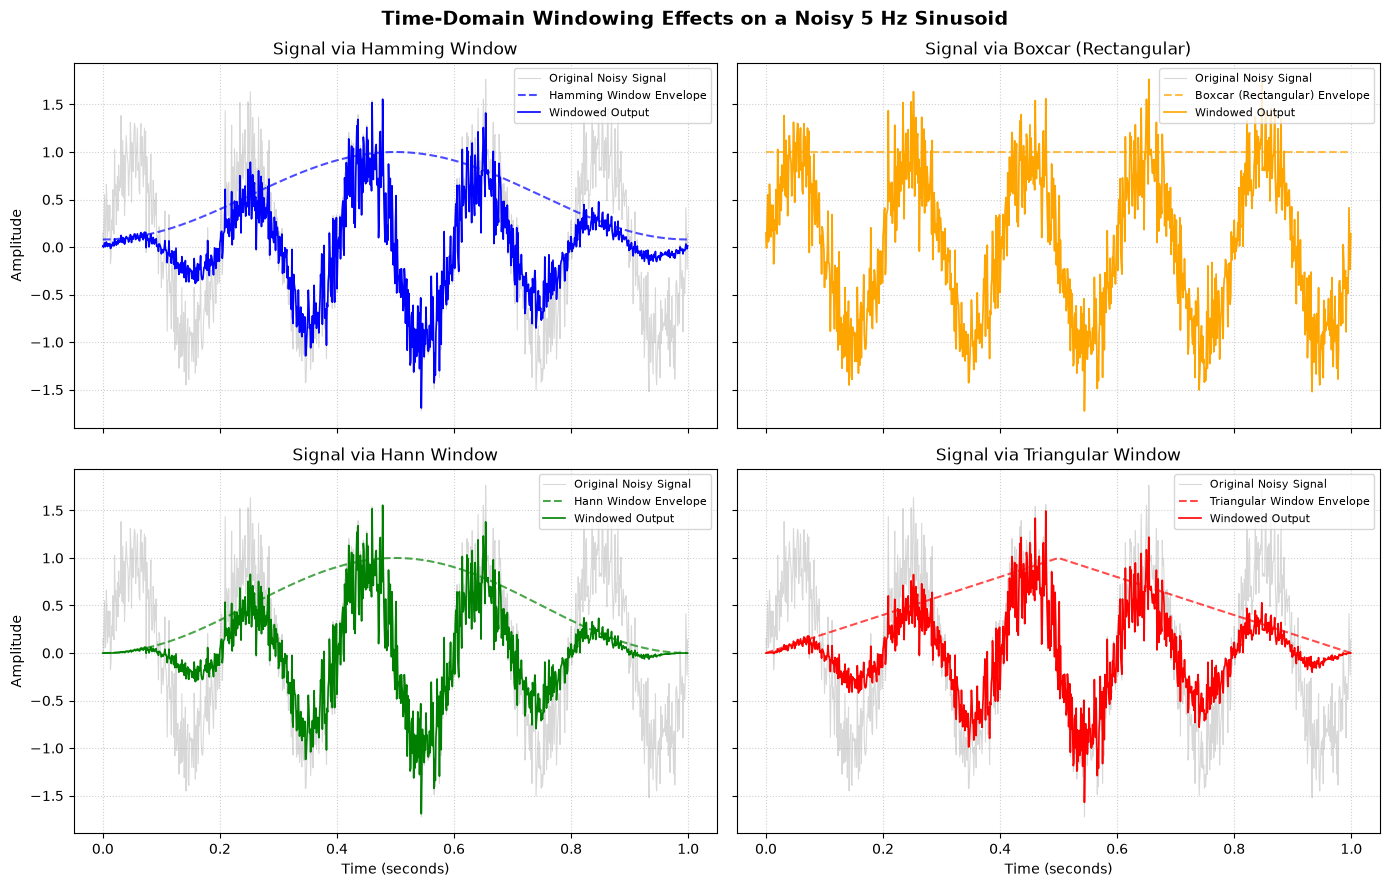

In [249]:
# 1. Set a random seed for reproducibility
np.random.seed(42)

# 2. Define parameters
fs = 1000          # Sampling frequency (Hz)
t_max = 1.0        # Duration in seconds
f = 5              # Frequency of the sine wave (Hz)
amplitude = 1.0    # Amplitude of the sine wave
noise_std = 0.3    # Standard deviation (intensity) of the noise

# 3. Generate time vector and clean sine wave
N = int(fs * t_max)
t = np.linspace(0, t_max, N, endpoint=False)
clean_signal = amplitude * np.sin(2 * np.pi * f * t)

# 4. Generate Gaussian noise and add it to the signal
noise = np.random.normal(loc=0.0, scale=noise_std, size=t.shape)
noisy_signal = clean_signal + noise

# 5. Generate matching length window functions
w_hamming = windows.hamming(N)
w_boxcar = windows.boxcar(N)
w_hann = windows.hann(N)
w_triang = windows.triang(N)

# 6. Create a 2x2 subplot grid demonstrating signal attenuation
fig, axs = plt.subplots(2, 2, figsize=(14, 9), sharex=True, sharey=True)

# Helper function to keep plot formatting concise
def plot_windowed_signal(ax, window_func, window_name, color):
    # Calculate the windowed effect on the noisy input signal
    windowed_signal = window_func * noisy_signal
    
    # Plot original noisy signal background, the window function envelop, and final output
    ax.plot(t, noisy_signal, label='Original Noisy Signal', color='gray', alpha=0.3, linewidth=0.8)
    ax.plot(t, window_func, label=f'{window_name} Envelope', color=color, linestyle='--', alpha=0.7)
    ax.plot(t, windowed_signal, label='Windowed Output', color=color, linewidth=1.2)
    
    ax.set_title(f'Signal via {window_name}')
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(loc='upper right', fontsize=8)

# Populate the 2x2 grid
plot_windowed_signal(axs[0, 0], w_hamming, 'Hamming Window', 'blue')
plot_windowed_signal(axs[0, 1], w_boxcar, 'Boxcar (Rectangular)', 'orange')
plot_windowed_signal(axs[1, 0], w_hann, 'Hann Window', 'green')
plot_windowed_signal(axs[1, 1], w_triang, 'Triangular Window', 'red')

# Set structural labels
for ax in axs[1, :]:
    ax.set_xlabel('Time (seconds)')
for ax in axs[:, 0]:
    ax.set_ylabel('Amplitude')

plt.suptitle(f"Time-Domain Windowing Effects on a Noisy {f} Hz Sinusoid", fontsize=14, weight='bold', y=0.98)
plt.tight_layout()
plt.show()

Except for the rectangular/boxcar window, these all force the boundaries to zero, with differing behavior in the middle of the signal.

While we can't see it visually, the different behavior of each window affects the **resolution** of our spectrum. If we could perfectly align edges between chunks and achieve true periodicity, the DFT wouldn't introduce artifacts at all...But this requires more aggressive smoothing over more of the window. This "smears" frequencies together, reducing our ability to accurately distinguish between frequency components.

We formalize this with the concepts of:
- **Mainlobe width**: Less aggressive smoothing can _increase_ resolution, allowing processing to identify more tightly separated frequencies, _but_ introduces artifact noise;
- **Sidelobe level**: The maximum power of the artifacts added to the entire spectrum. If powerful enough, they can mask real components with lower power.

This is the crux of it:
- Tapered windows—like Hann, Hamming, or the Triangular example—_expand_ mainlobe width, reducing resolution along with artifact noise.
- Less tapered windows, like the boxcar, have tighter mainlobes, but introduce artifact noise.

Let's quantify this effect for the windows above. We'll do two by hand:
- Boxcar
- Hamming

...And then run a head-to-head to compute metrics for the remainder.

## Frequency Responses of Common Windows

At this point, we're interested in the effect these windows have on the _spectrum_ we generate after applying them. The "purest" situation would be applying the window to a uniform signal of all ones; since windowing is just multiplication, this reduces to the window itself.

So, we can study the impact of each window by:
- Computing its FFT
- Plotting its spectrum
- Studying its **mainlobe width**, corresponding to its maximum resolution; and **sidelobe level**, corresponding to the "loudness" of the artifact noise/the level below which real signals will be suppressed.

This is equivalent to studying the **frequency response** of each window.

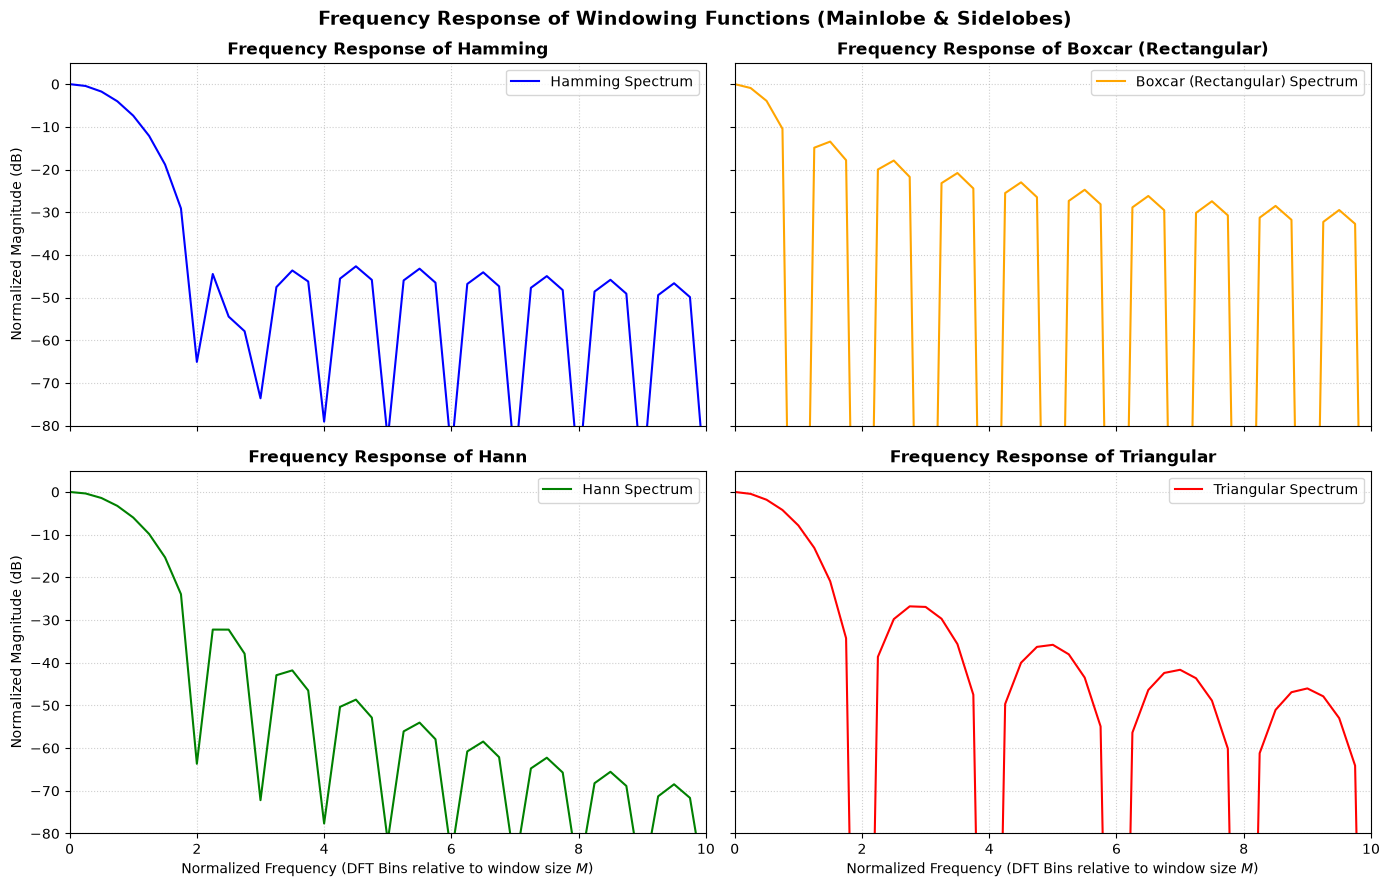

In [402]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal.windows as windows

# 1. Define window and padding parameters
M = 512          # Window length in samples
n_fft = 2048     # Zero-padded FFT length for smooth spectral curves

# 2. Generate the window profiles
w_dict = {
    'Hamming': windows.hamming(M),
    'Boxcar (Rectangular)': windows.boxcar(M),
    'Hann': windows.hann(M),
    'Triangular': windows.triang(M)
}

# 3. Create the 4-up subplot grid for frequency responses
fig, axs = plt.subplots(2, 2, figsize=(14, 9), sharex=True, sharey=True)
axs = axs.ravel() # Flatten grid for easy indexing

# Generate frequency bins normalized to bin index units for cross-window comparison
# Using rfftfreq with d=1 gives normalized digital frequencies (cycles/sample)
freqs = np.fft.rfftfreq(n_fft, d=1)
# Convert to DFT bin units relative to original window length M for explicit lobe counting
bins = freqs * M  

for i, (name, w) in enumerate(w_dict.items()):
    # Compute the Real FFT and pad with zeros to n_fft
    w_fft = np.fft.rfft(w, n=n_fft)
    magnitude = np.abs(w_fft)
    
    # Avoid log10(0) warning by adding a tiny epsilon floor
    magnitude = np.clip(magnitude, a_min=1e-10, a_max=None)
    
    # Normalize magnitude response relative to its mainlobe peak and convert to dB
    response_db = 20 * np.log10(magnitude / magnitude.max())
    
    # Assign distinct colors to match previous time-domain plots
    color = ['blue', 'orange', 'green', 'red'][i]
    
    # Plot the frequency spectrum
    axs[i].plot(bins, response_db, color=color, linewidth=1.5, label=f'{name} Spectrum')
    
    # Format individual axes
    axs[i].set_title(f'Frequency Response of {name}', weight='semibold')
    axs[i].set_ylim(-80, 5) # Lock y-axis to see deep into the sidelobe floor
    axs[i].grid(True, which='both', linestyle=':', alpha=0.6)
    axs[i].legend(loc='upper right')

# Standardize x-axis bounds to isolate the mainlobe and near-field sidelobes
plt.xlim(0, 10)

# Set global layout labels
for ax in [axs[2], axs[3]]:
    ax.set_xlabel('Normalized Frequency (DFT Bins relative to window size $M$)')
for ax in [axs[0], axs[2]]:
    ax.set_ylabel('Normalized Magnitude (dB)')

plt.suptitle("Frequency Response of Windowing Functions (Mainlobe & Sidelobes)", fontsize=14, weight='bold', y=0.98)
plt.tight_layout()
plt.show()

Immediately, we see a few properties not obvious from the time-domain plots:
- The width of the mainlobe (the centermost region) varies more than was obvious in the time domain.
- Sidelobe levels (the loudness of artifact noise, represented by the height of the rightmost swells) vary considerably across windows.
- Sidelobe levels _decay differently_ with different windows; this is called **roll-off rate**, and as another metric we can use to evaluate windows.

## Characterizing the Boxcar Window

Let's compute:
- Mainlobe Width
- Sidelobe Level
- Rolloff Rate (`np.polyfit`)

To find the mainlobe width, we find the first bin in which the signal begins to _rise_ after falling. Note that, in our plots, our mainlobe is represented by only _half_ of the bandwidth of the full mainlobe; so, we'll have to double the bin count we're about to come up with.

In [436]:
def compute_mainlobe_width(spectrum, full_bandwidth: bool = True):
    mag = np.abs(spectrum)
    for i, m in enumerate(mag):
        if mag[i + 1] > mag[i]:
            return 2 * i if full_bandwidth else i

In [318]:
def to_bins(ml_width: int, M: int, n_fft: int):
    return ml_width * M / n_fft

In [437]:
boxcar_fft = np.fft.rfft(w_dict['Boxcar (Rectangular)'], n=n_fft)

In [438]:
to_bins(compute_mainlobe_width(boxcar_fft), M, n_fft)

2.0

So the boxcar filter has a mainlobe width of **2 bins**. That's...Not very physical, but the specific range of frequencies that covers depends on **sampling rate** and **number of samples in the DFT**. For our sample, we compute:

$$
\Delta f = \frac{f_{s}}{N} = \frac{1000}{2048} \approx 1.95 \space \text{Hz}
$$

...So our boxcar filter could distinguish signals differing by just under 4 Hz. 

Next, we compute **sidelobe level**. This is just the maximum level outside of the region of the mainlobe.

In [439]:
def compute_sidelobe_level(spectrum):
    # to decibles
    mag = np.abs(spectrum)
    # avoid divide by zero in log10
    mag = np.clip(mag, a_min=1e-10, a_max=None)
    db_spectrum = 20 * np.log10(mag / mag.max())
    # mainlobe region
    ml_width = compute_mainlobe_width(spectrum, full_bandwidth=False)
    return max(db_spectrum[ml_width:])

In [440]:
compute_sidelobe_level(boxcar_fft)

np.float64(-13.464700002201921)

The first sidelobe of the boxcar window sits about -13.46 dB _below_ the level of the mainlobe. Anything _quieter_ than -17.9 dB relative to the mainlobe will be masked by the sidelobes.

As we'll see, this isn't great for sidelobe level. _But_, boxcar has very high 2-bin mainlobe width; we'll see this tradeoff is intrinsic.

Finally, let's compute rolloff rate. We need to:
- Isolate the sidelobe peaks
- Log-transform
- Fit a line
- Report the slope in dB

...This is a bit annoying, but let's get it done.

In [334]:
import scipy.signal

In [408]:
# need frequencies...
boxcar_fft_freqs = np.fft.rfftfreq(n_fft, d=1)

In [443]:
def compute_rolloff_rate(spectrum, freqs, min_prominence: float = 3.0):
    # omit DC region
    ml_width = compute_mainlobe_width(spectrum, full_bandwidth=False)
    # magnitude, normalize, avoid divide by zero at main spike
    mag = np.abs(spectrum)
    mag = np.clip(mag, a_min=1e-10, a_max=None)
    # decibel conversion
    db_spectrum = 20 * np.log10(mag / mag.max())
    # find peaks
    indices, _ = scipy.signal.find_peaks(
        db_spectrum,
        prominence=min_prominence,
    )
    peak_freqs = freqs[indices]
    peak_dbs = db_spectrum[indices]
    # ignore DC: TODO
    valid = peak_freqs > 0
    x_log = np.log10(peak_freqs[valid])
    y_db = peak_dbs[valid]

    # compute rolloff: TODO
    slope, _ = np.polyfit(x_log, y_db, 1)
    rolloff_per_octave = slope * np.log10(2)

    return rolloff_per_octave

In [444]:
compute_rolloff_rate(boxcar_fft, boxcar_fft_freqs)

np.float64(-5.370461063851136)

The theoretical number we want to see is -6.02 dB; you can [compute this analytically](https://ccrma.stanford.edu/~jos/sasp/Rectangular_Window_Side_Lobes.html). The reason we're off is due to the fact 6.02 dB is predicted by the analytical solution; we're hitting limitations due to discrete sampling. 

We'll revisit that later; we're on the right track.

In summary, the boxcar window has the following characteristics:
- **Mainlobe width** of 2 bins
- **First sidelobe level** of about -13 dB
- **Theoretical rolloff per octave** of -6.02 dB (computed at -5.37 dB)

## Characterizing the Hamming Window

Let's compute:
- Mainlobe Width
- Sidelobe Level
- Rolloff Rate (`np.polyfit`)

We can just reuse our functions.

In [446]:
hamming_fft = np.fft.rfft(w_dict['Hamming'], n=n_fft)

In [447]:
to_bins(compute_mainlobe_width(hamming_fft), M, n_fft)

4.0

So the Hamming window has _lower_ resolution, with a mainlobe width of 4 bins. In our case, that corresponds to a resolution of just under 8 Hz.

In [448]:
compute_sidelobe_level(hamming_fft)

np.float64(-42.673067538344156)

In exchange for lower resolution, the Hamming window offers dramatically better first sidelobe level; this is the whole tradeoff.

In [449]:
hamming_fft_freqs = np.fft.rfftfreq(n_fft, d=1)

In [450]:
compute_rolloff_rate(hamming_fft, hamming_fft_freqs)

np.float64(-5.0240909276342105)

We expect -6 dB rolloff for the Hamming window too, so we'll chalk this up to estimation error as well.

## Window Head-to-Head

Inspecting the rest is just loops at this point; here are their characteristics.

In [153]:
# TODO

We'll use Hamming; we won't need to manipulate window type very much, but it's important to understand the influence it has on your results.

## Computing Spectrograms

With that out of the way, we can complete our implementation.

All that's left is:
- Enframe the signal, properly, with a window
- Perform an FFT on each frame
- Map each frame's timestamp to the FFT's spectrum

[Refer to Downey](https://allendowney.github.io/ThinkDSP2/chap03.html#implementing-spectrograms) and [his code](https://github.com/AllenDowney/ThinkX/blob/master/thinkdsp.py).

Compared to everything else, this is refreshingly straightforward.

In [154]:
# TODO: implement

Great; let's compute a spectrogram of our test signal.

In [155]:
# TODO: test on mixed sound

Still some artifacts, but this looks about as expected.

Let's try it on a vowel.

In [156]:
# TODO: on a Hillenbrand vowel, but with window of 5 ms

That's...Less encouraging. We know from the data that we have the frequencies below in the spectrum...But, we see none.

TODO: Expound analysis [here](https://courses.grainger.illinois.edu/ece417/fa2019/slides/spectrograms1_wideband_narrowband.html) and [here](https://www.its.caltech.edu/~matilde/GaborLocalization.pdf).

...So we have a choice to make:
- **Wideband** ...
- **Narrowband** ...

Before, our window was too long to resolve formants. If we reduce the window size, we should be able to resolve them; our bandwidth analysis above suggests an upper bound on the window length, so let's set it to 5 ms.

In [159]:
# TODO: show

And we're in business: This visualizes precisely the frequencies we expect.

In [158]:
for n, f in zip(formant_names, formant_frequencies_ss):
    print(f'{n}: {f} Hz')

f0: 174
f1: 663
f2: 2012.0
f3: 2659.0
f4: 3691.0


## Mel Spectrograms

One last technicality.

The spectrogram above uses a linear scale. But, loudness scales logarithmically. To make a sound twice as loud, you must make it _ten times more powerful_. That means you get huge ranges of power on spectrograms: Quiet signals might land near zero, while moderately loud ones might be measured in figures orders of magnitude larger.

More importantly. It's not just loudness that humans perceive logarithmically, but also pitch.

In other words, we perceive pitch in terms of _ratios_, not absolute frequency.

That didn't make sense to me at first, so think of it this way: If you play A4 (440 Hz) and A5 (880 Hz), we perceive the same note, one octave higher, and interpret it as a "doubling"; musicians even phrase it this way intuitively. If you play C4 (261.63 Hz) and C5 (523.26 Hz), we perceive the same thing, despite the frequencies being different, because the _ratio_ is the same.

The point is: We'll want to log-transform our data to compress dynamic range, but also account for the psychoacoustic phenomenon of logarithmic pitch perception.

The most common way to do this is with the [Mel scale](https://en.wikipedia.org/wiki/Mel_scale), or the [Bark scale](https://en.wikipedia.org/wiki/Bark_scale). They're empirically derived log transformations of frequency into pitch classes, based on studies of human perception. For instance, the Mel scale applies this transformation:

$$
m = 2595 \log_{10} (1 + \frac{f}{700})
$$

In principle, this is supposed to produce a feature set that more closely reflects human perception. I'm not entirely sure I buy that, but it's standard practice.

Librosa has a Mel transformation for us, so we won't implement our own; it even has a handy method for using the transform to generate spectrograms.

In [ ]:
# TODO: 

Note that this preserves the basic shape of the spectrogram, but compresses its dynamic range (check the y-axis).